# 03 — Entraînement des modèles de prédiction du RUL

## Objectif du notebook

Entraîner trois modèles de **régression supervisée** pour prédire le RUL :
1. **Linear Regression** — modèle de référence simple.
2. **Random Forest Regressor** — ensemble d'arbres de décision construits en parallèle.
3. **Gradient Boosting Regressor** — ensemble d'arbres construits l'un après l'autre.

Chaque modèle est évalué sur l'ensemble de **validation** (20 moteurs jamais vus pendant l'entraînement)
avec trois métriques : **MAE**, **RMSE** et **R²**.

## 1. Importations et chargement des données préparées

In [1]:
# Importation des bibliothèques
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 90
RANDOM_STATE = 42

In [2]:
# Chargement des données préparées dans le notebook 02
train_set = pd.read_csv("../data/processed/train_set.csv")
validation_set = pd.read_csv("../data/processed/validation_set.csv")

# Chargement des transformations
preprocessing = joblib.load("../models/preprocessing.pkl")
scaler = preprocessing["scaler"]
feature_columns = preprocessing["feature_columns"]

# Variables d'entrée normalisées (X) et cible (y)
X_train = scaler.transform(train_set[feature_columns])
y_train = train_set["RUL"].values

X_validation = scaler.transform(validation_set[feature_columns])
y_validation = validation_set["RUL"].values

print("X_train      :", X_train.shape)
print("X_validation :", X_validation.shape)

X_train      : (16340, 43)
X_validation : (4291, 43)


## 2. Les métriques d'évaluation

| Métrique | Formule | Interprétation |
|---|---|---|
| **MAE** | $\frac{1}{n}\sum \lvert y - \hat{y}\rvert$ | erreur moyenne en cycles |
| **RMSE** | $\sqrt{\frac{1}{n}\sum (y - \hat{y})^2}$ | pénalise davantage les grosses erreurs |
| **R²** | $1 - \frac{\sum (y-\hat{y})^2}{\sum (y-\bar{y})^2}$ | part de la variance expliquée (1 = parfait) |

On écrit une petite fonction pour calculer les trois métriques.

In [3]:
def evaluate_model(y_true, y_predicted):
    """Calcule MAE, RMSE et R² et les retourne dans un dictionnaire."""
    mae = mean_absolute_error(y_true, y_predicted)
    rmse = np.sqrt(mean_squared_error(y_true, y_predicted))
    r2 = r2_score(y_true, y_predicted)
    return {"MAE": round(float(mae), 2), "RMSE": round(float(rmse), 2), "R2": round(float(r2), 4)}


def plot_predictions(y_true, y_predicted, model_name):
    """Affiche valeurs réelles vs prédites et la distribution des erreurs."""
    errors = y_predicted - y_true

    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

    # Nuage de points réel / prédit
    axes[0].scatter(y_true, y_predicted, s=4, alpha=0.3, color="#1f4e79")
    axes[0].plot([0, 130], [0, 130], "--", color="#c0392b", label="Prédiction parfaite")
    axes[0].set_xlabel("RUL réel")
    axes[0].set_ylabel("RUL prédit")
    axes[0].set_title(model_name + " — réel vs prédit (validation)")
    axes[0].legend()

    # Histogramme des erreurs
    sns.histplot(errors, bins=50, ax=axes[1], color="#2e86c1")
    axes[1].axvline(0, color="#c0392b", linestyle="--")
    axes[1].set_xlabel("Erreur (prédit − réel) en cycles")
    axes[1].set_title(model_name + " — distribution des erreurs")
    plt.tight_layout()
    plt.show()

## 3. Modèle 1 — Linear Regression

### Principe
La régression linéaire cherche une combinaison linéaire des variables :

$$\hat{RUL} = w_0 + w_1 x_1 + w_2 x_2 + \dots + w_n x_n$$

Les coefficients $w_i$ sont calculés pour minimiser l'erreur quadratique (méthode des moindres carrés).

### Paramètres
Aucun hyperparamètre à régler (paramètres par défaut de scikit-learn).

### Avantages / limites
- ✅ Très rapide, simple, interprétable (un coefficient par variable).
- ❌ Ne peut représenter que des relations **linéaires** : or la dégradation s'accélère en fin de vie
  et le RUL est plafonné à 125, ce qui est fortement non linéaire.

In [4]:
# Création et entraînement du modèle
linear_model = LinearRegression()

start_time = time.time()
linear_model.fit(X_train, y_train)
print("Temps d'entraînement : %.2f s" % (time.time() - start_time))

# Prédiction sur la validation
linear_predictions = linear_model.predict(X_validation)

# Évaluation
linear_metrics = evaluate_model(y_validation, linear_predictions)
print("Linear Regression — validation :", linear_metrics)
print("RUL prédit minimum : %.1f — maximum : %.1f" % (linear_predictions.min(), linear_predictions.max()))

Temps d'entraînement : 0.04 s
Linear Regression — validation : {'MAE': 14.29, 'RMSE': 17.52, 'R2': 0.8219}
RUL prédit minimum : -39.3 — maximum : 167.3


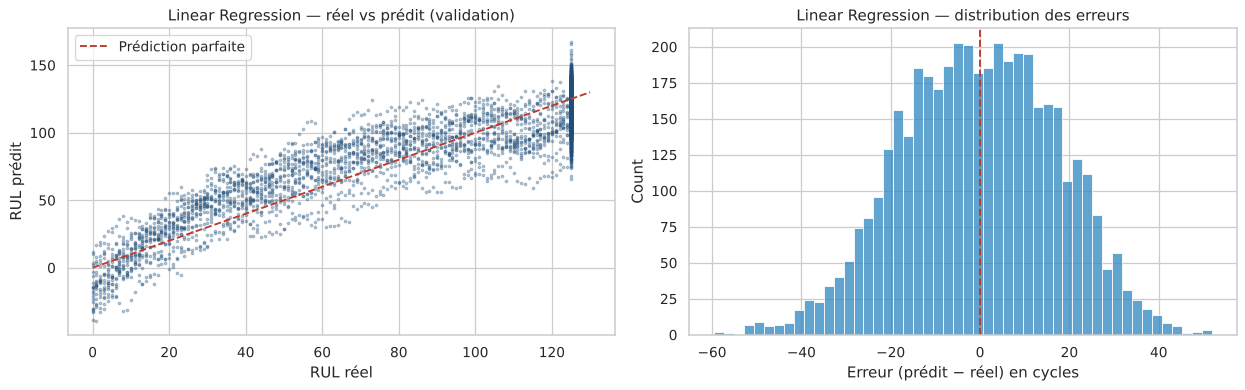

In [5]:
plot_predictions(y_validation, linear_predictions, "Linear Regression")

**Interprétation :** un modèle linéaire ne peut pas reproduire le plateau à 125 : les points
forment un nuage « tordu » autour de la diagonale et certaines prédictions sortent de l'intervalle
[0, 125] (voir le minimum et le maximum affichés). C'est notre **niveau de référence**.

## 4. Modèle 2 — Random Forest Regressor

### Principe
Une forêt aléatoire construit **de nombreux arbres de décision**, chacun entraîné sur un
échantillon aléatoire des données (*bootstrap*) et en ne regardant qu'une partie des variables
à chaque division. La prédiction finale est la **moyenne** des prédictions de tous les arbres.
Moyenner beaucoup d'arbres différents réduit fortement le sur-apprentissage d'un arbre seul.

### Paramètres utilisés
| Paramètre | Valeur | Rôle |
|---|---|---|
| `n_estimators` | 150 | nombre d'arbres |
| `max_depth` | 12 | profondeur maximale de chaque arbre (limite le sur-apprentissage) |
| `min_samples_leaf` | 5 | nombre minimum d'exemples dans une feuille |
| `max_features` | 0.5 | proportion de variables testées à chaque division |
| `random_state` | 42 | reproductibilité |

In [6]:
random_forest_model = RandomForestRegressor(
    n_estimators=150,
    max_depth=12,
    min_samples_leaf=5,
    max_features=0.5,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

start_time = time.time()
random_forest_model.fit(X_train, y_train)
print("Temps d'entraînement : %.2f s" % (time.time() - start_time))

random_forest_predictions = random_forest_model.predict(X_validation)
random_forest_metrics = evaluate_model(y_validation, random_forest_predictions)
print("Random Forest — validation :", random_forest_metrics)

Temps d'entraînement : 12.51 s
Random Forest — validation : {'MAE': 10.43, 'RMSE': 14.96, 'R2': 0.8702}


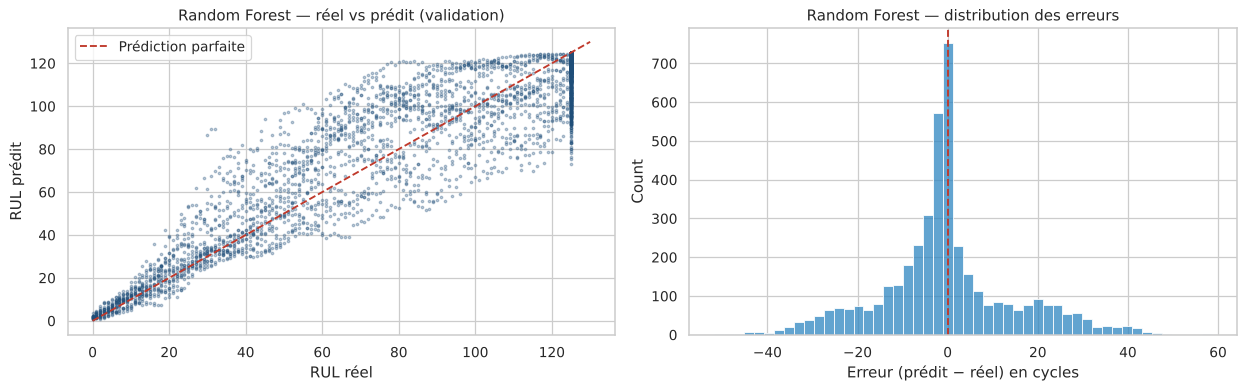

In [7]:
plot_predictions(y_validation, random_forest_predictions, "Random Forest")

**Interprétation :** les arbres reproduisent naturellement le plateau à 125 et la
décroissance en fin de vie. Les prédictions restent dans l'intervalle [0, 125].

## 5. Modèle 3 — Gradient Boosting Regressor

### Principe
Le *boosting* construit des arbres **les uns après les autres**. Chaque nouvel arbre (peu profond)
est entraîné à prédire les **erreurs résiduelles** commises par les arbres précédents.
La prédiction finale est la somme des contributions de tous les arbres, chacune multipliée
par un *learning rate* (taux d'apprentissage) pour avancer prudemment.

### Paramètres utilisés
| Paramètre | Valeur | Rôle |
|---|---|---|
| `n_estimators` | 300 | nombre d'arbres successifs |
| `learning_rate` | 0.05 | poids de chaque nouvel arbre |
| `max_depth` | 4 | arbres peu profonds (« apprenants faibles ») |
| `subsample` | 0.8 | chaque arbre voit 80 % des données (régularisation) |
| `random_state` | 42 | reproductibilité |

In [8]:
gradient_boosting_model = GradientBoostingRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    random_state=RANDOM_STATE,
)

start_time = time.time()
gradient_boosting_model.fit(X_train, y_train)
print("Temps d'entraînement : %.2f s" % (time.time() - start_time))

gradient_boosting_predictions = gradient_boosting_model.predict(X_validation)
gradient_boosting_metrics = evaluate_model(y_validation, gradient_boosting_predictions)
print("Gradient Boosting — validation :", gradient_boosting_metrics)

Temps d'entraînement : 49.56 s
Gradient Boosting — validation : {'MAE': 10.32, 'RMSE': 14.58, 'R2': 0.8767}


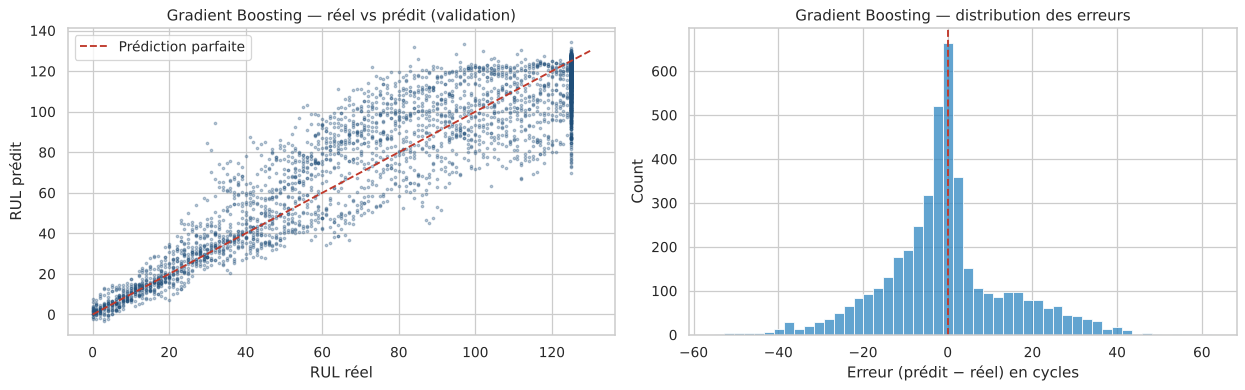

In [9]:
plot_predictions(y_validation, gradient_boosting_predictions, "Gradient Boosting")

## 6. Courbe d'apprentissage du Gradient Boosting

`staged_predict` donne la prédiction après chaque arbre ajouté : on vérifie que l'erreur de
validation diminue puis se stabilise (pas de sur-apprentissage marqué).

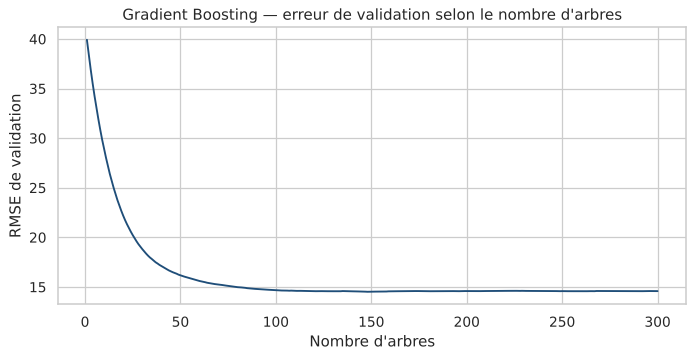

In [10]:
validation_rmse_by_stage = []
for stage_predictions in gradient_boosting_model.staged_predict(X_validation):
    stage_rmse = np.sqrt(mean_squared_error(y_validation, stage_predictions))
    validation_rmse_by_stage.append(stage_rmse)

plt.figure(figsize=(9, 4))
plt.plot(range(1, len(validation_rmse_by_stage) + 1), validation_rmse_by_stage, color="#1f4e79")
plt.xlabel("Nombre d'arbres")
plt.ylabel("RMSE de validation")
plt.title("Gradient Boosting — erreur de validation selon le nombre d'arbres")
plt.show()

## 7. Exemple : prédictions sur un moteur de validation

On suit l'évolution du RUL prédit par les trois modèles pour un moteur complet.

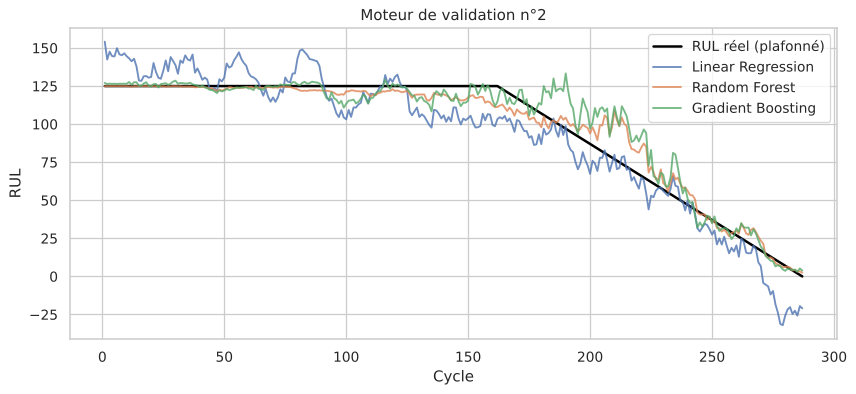

In [11]:
example_engine = validation_set["unit_id"].unique()[0]
engine_mask = (validation_set["unit_id"] == example_engine).values

plt.figure(figsize=(11, 4.5))
plt.plot(validation_set.loc[engine_mask, "cycle"], y_validation[engine_mask],
         color="black", linewidth=2, label="RUL réel (plafonné)")
plt.plot(validation_set.loc[engine_mask, "cycle"], linear_predictions[engine_mask],
         label="Linear Regression", alpha=0.8)
plt.plot(validation_set.loc[engine_mask, "cycle"], random_forest_predictions[engine_mask],
         label="Random Forest", alpha=0.8)
plt.plot(validation_set.loc[engine_mask, "cycle"], gradient_boosting_predictions[engine_mask],
         label="Gradient Boosting", alpha=0.8)
plt.title("Moteur de validation n°" + str(example_engine))
plt.xlabel("Cycle")
plt.ylabel("RUL")
plt.legend()
plt.show()

## 8. Sauvegarde des trois modèles

Les trois modèles sont enregistrés dans `models/candidates/`. Le choix du meilleur modèle
est fait dans le notebook 04.

In [12]:
os.makedirs("../models/candidates", exist_ok=True)
joblib.dump(linear_model, "../models/candidates/linear_regression.pkl")
joblib.dump(random_forest_model, "../models/candidates/random_forest.pkl", compress=3)
joblib.dump(gradient_boosting_model, "../models/candidates/gradient_boosting.pkl", compress=3)

# Récapitulatif des métriques de validation
summary = pd.DataFrame(
    [linear_metrics, random_forest_metrics, gradient_boosting_metrics],
    index=["Linear Regression", "Random Forest", "Gradient Boosting"],
)
summary

,MAE,RMSE,R2
Linear Regression,14.29,17.52,0.8219
Random Forest,10.43,14.96,0.8702
Gradient Boosting,10.32,14.58,0.8767


## 9. Conclusion

Les trois modèles ont été réellement entraînés sur 80 moteurs et évalués sur 20 moteurs de validation.
Les résultats ci-dessus sont ceux obtenus lors de l'exécution de ce notebook.
Les modèles à base d'arbres capturent la non-linéarité du RUL beaucoup mieux que la régression linéaire.
La comparaison détaillée et le choix du modèle final sont présentés dans le notebook 04.